# Recurrent Networks for Text

A recurrent network reads a text **one word at a time** and keeps a **hidden state** that summarizes what it has read. In this notebook we use it to classify the **sentiment** of movie review sentences: an embedding layer, a recurrent cell, and a linear layer that gives the class.

We train the networks with **skorch**, as we did for the MLP, and we compare the three recurrent cells (**vanilla RNN, LSTM and GRU**), two ways to summarize the text (the **last state** or the **mean** of all the states), and **pretrained word vectors**.

The corpus is the **Stanford Sentiment Treebank** (Socher et al., 2013), in its binary version: sentences from Rotten Tomatoes movie reviews, labelled **positive** or **negative** by human annotators (the neutral ones are removed). The sentences are short, around 20 words, so the networks train in a few seconds.

In [1]:
# Run once if you are not using the course environment.
# %pip install -q numpy pandas matplotlib scikit-learn torch gensim

In [2]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping, EpochScoring
from skorch.dataset import Dataset
from skorch.helper import predefined_split

import gensim.downloader as api

In [3]:
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

MAX_LEN = 60  # words per sentence (the longest sentence has 56)
EMBEDDING = 50  # size of the word vectors
HIDDEN = 64  # size of the hidden state
BATCH = 256  # lower if you run out of memory on your GPU 
MAX_EPOCHS = 50

print("device:", DEVICE)

device: mps


---
## The data

The dataset comes already split in **training**, **validation** and **test** sentences. Each sentence has a label: `1` for positive, `0` for negative. We use the validation sentences to compare the models, and the **test sentences only at the end**.

In [4]:
train = pd.read_csv("Data/sst_train.csv")
valid = pd.read_csv("Data/sst_valid.csv")
test = pd.read_csv("Data/sst_test.csv")

print(len(train), "training,", len(valid), "validation,", len(test), "test sentences")
print("positive sentences in the training set:", round(train.label.mean(), 2))
print("average number of words:", round(train.text.str.split().str.len().mean(), 1))
print()
for text, label in zip(train.text[:3], train.label[:3]):
    print(label, text)

6920 training, 872 validation, 1821 test sentences
positive sentences in the training set: 0.52
average number of words: 19.3

1 a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films
0 apparently reassembled from the cutting-room floor of any given daytime soap .
0 they presume their audience wo n't sit still for a sociology lesson , however entertainingly presented , so they trot out the conventional science-fiction elements of bug-eyed monsters and futuristic women in skimpy clothes .


A network needs numbers, so every sentence goes through four steps:

1. **tokenization**: the sentences are already lowercase, with the punctuation separated by spaces, so splitting on the spaces is enough;
2. **vocabulary**: every word that occurs at least 2 times in the training sentences gets an integer ID. Two IDs are special: `0` is the **padding**, `1` is for the **unknown** words;
3. **truncation and padding**: sentences are cut after `MAX_LEN` words, and shorter ones are filled with `0`, so that they all have the same length and can be grouped in a batch;
4. the network ignores the padding: we know that `0` is not a word.

In [5]:
counts = Counter(w for text in train.text for w in text.split())
vocab = ["<pad>", "<unk>"] + [w for w, c in counts.items() if c >= 2]
word_to_id = {w: i for i, w in enumerate(vocab)}

print("vocabulary:", len(vocab), "words")
print(vocab[:12])

vocabulary: 7142 words
['<pad>', '<unk>', 'a', 'stirring', ',', 'funny', 'and', 'finally', 'transporting', 'of', 'beauty', 'the']


In [12]:
def encode(texts):
    ids = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for i, text in enumerate(texts):
        # for each word in the sentence, get its ID from the dictionary, or 1 if it is unknown
        words = [word_to_id.get(w, 1) for w in text.split()][:MAX_LEN]
        ids[i, :len(words)] = words
    return ids

X_train, X_valid, X_test = encode(train.text), encode(valid.text), encode(test.text)
y_train, y_valid, y_test = train.label.values, valid.label.values, test.label.values

print("the first sentence:", train.text[0])
print("as word IDs:", X_train[0, :25].tolist())
print("shape of the training matrix:", X_train.shape)

the first sentence: a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films
as word IDs: [2, 3, 4, 5, 6, 7, 8, 1, 9, 10, 6, 11, 12, 6, 1, 13, 14, 0, 0, 0, 0, 0, 0, 0, 0]
shape of the training matrix: (6920, 60)


---
## A baseline without recurrence

How well does a model that **ignores the order** of the words do? A logistic regression on TF-IDF vectors is the reference for the networks.

In [14]:
tfidf = TfidfVectorizer(sublinear_tf=True)
T_train = tfidf.fit_transform(train.text)
baseline = LogisticRegression(max_iter=1000).fit(T_train, y_train)
baseline.score(tfidf.transform(valid.text), y_valid)

0.7878440366972477

---
## The model

The network has three parts:

- an **embedding layer** that turns every word ID into a vector;
- a **recurrent cell** (`RNN`, `LSTM` or `GRU`) that reads the vectors in order and gives a hidden state **for every word**;
- a **linear layer** that turns a summary of the text into **two numbers**, one for each class (negative and positive). A **softmax** turns them into two probabilities that sum to 1, and the loss is the **cross-entropy**.

The summary can be the hidden state of the **last word** of the sentence, or the **mean** of all the hidden states. The padding is ignored in both cases.

**skorch** wraps the module in an object with `fit`, `predict` and `score`, and it runs the training loop for us: the mini-batches, the forward and the backward pass, the update of the weights, and the loss and the accuracy on the validation sentences after every epoch. We use the **cross-entropy** loss, the **Adam** optimizer, a callback that also measures the accuracy on the training sentences, and **early stopping**: the training stops when the validation accuracy has not improved for 3 epochs, and the weights of the best epoch are restored.

---
## Vanilla RNN, LSTM and GRU

First experiment: the same network with the three cells, using the **last hidden state** as the summary of the sentence.

Every network goes through **three steps**, each in its own cell: we **define** it (the module, the loss, the optimizer, the callbacks), we **train** it with `fit`, and we **plot** the loss and the accuracy of the training and of the validation sentences, epoch after epoch.

In [15]:
valid_ds = Dataset(X_valid, y_valid)  # the validation sentences, for skorch
nets = {}

### Vanilla RNN

The network is a PyTorch module (`nn.Module`): `__init__` creates the layers, `forward` says how the numbers flow through them. For a batch of sentences (word IDs), the embedding layer gives a vector for every word, the `RNN` layer gives a hidden state for every word, and we keep **the state of the last word** (we find it with the real length of the sentence: the padding is not a word). The linear layer gives the two scores of the classes: the softmax is inside the loss.

In [32]:
class RNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBEDDING, padding_idx=0)
        self.rnn = nn.RNN(EMBEDDING, HIDDEN, batch_first=True)
        self.out = nn.Linear(HIDDEN, 2)  # one output for each class

    def forward(self, ids):
        # the real length of every sentence (clamp to avoid 0)
        lengths = (ids != 0).sum(dim=1).clamp(min=1)  

        # one hidden state for every word, for every sentence
        states, _ = self.rnn(self.embedding(ids)) 

        # the state of the last word for every sentence (different sentences have different lengths)
        last = states[torch.arange(len(ids), device=ids.device), lengths - 1]
        
        return self.out(last)

In [33]:
torch.manual_seed(0)
net_rnn_last = NeuralNetClassifier(
    RNNClassifier,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    lr=2e-3,
    batch_size=BATCH,
    max_epochs=MAX_EPOCHS,
    iterator_train__shuffle=True,  # skorch does not shuffle the training sentences by default
    train_split=predefined_split(valid_ds),
    callbacks=[
        EpochScoring(scoring="accuracy", name="train_acc", on_train=True, lower_is_better=False),
        EarlyStopping(monitor="valid_acc", patience=5, lower_is_better=False, load_best=True),
    ],
    device=DEVICE,
)

In [34]:
net_rnn_last.fit(X_train, y_train)
nets["rnn, last state"] = net_rnn_last

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5357        0.6927       0.5333        0.6846  0.9711
      2       0.5754        0.6714       0.5998        0.6633  0.5897
      3       0.6341        0.6377       0.6479        0.6273  0.5689
      4       0.6870        0.5915       0.6755        0.6080  0.5453
      5       0.7302        0.5378       0.6606        0.6411  0.8274
      6       0.7749        0.4811       0.7076        0.5895  0.6092
      7       0.8048        0.4380       0.7099        0.5887  0.5929
      8       0.8415        0.3753       0.7339        0.6388  0.5513
      9       0.8695        0.3240       0.7351        0.6242  0.6039
     10       0.8909        0.2770       0.7431        0.6351  0.7515
     11       0.9079        0.2446       0.7466        0.6468  0.7234
     12       0.9130        0.2314       0.7466        0.6589  0.6129
     13       0.9311

best validation accuracy 0.750 at epoch 14


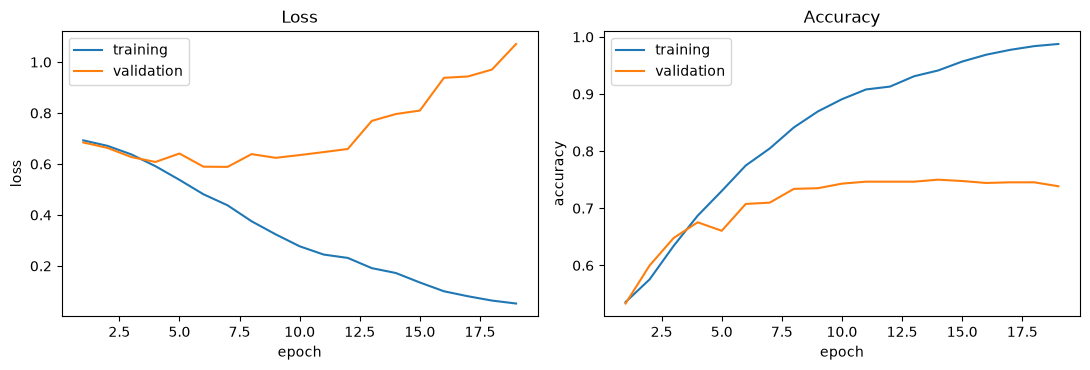

In [35]:
history = net_rnn_last.history
epochs = np.arange(1, len(history) + 1)
print(f"best validation accuracy {max(history[:, 'valid_acc']):.3f} at epoch {np.argmax(history[:, 'valid_acc']) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, history[:, "train_loss"], label="training")
axes[0].plot(epochs, history[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, history[:, "train_acc"], label="training")
axes[1].plot(epochs, history[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### LSTM

The same network, with an `LSTM` layer instead of the `RNN` layer.

In [36]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBEDDING, padding_idx=0)
        self.lstm = nn.LSTM(EMBEDDING, HIDDEN, batch_first=True)
        self.out = nn.Linear(HIDDEN, 2)  # one output for each class

    def forward(self, ids):
        lengths = (ids != 0).sum(dim=1).clamp(min=1)  # the real length of every sentence
        states, _ = self.lstm(self.embedding(ids))  # one hidden state for every word
        last = states[torch.arange(len(ids), device=ids.device), lengths - 1]  # the state of the last word
        return self.out(last)

In [37]:
torch.manual_seed(0)
net_lstm_last = NeuralNetClassifier(
    LSTMClassifier,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    lr=2e-3,
    batch_size=BATCH,
    max_epochs=MAX_EPOCHS,
    iterator_train__shuffle=True,  # skorch does not shuffle the training sentences by default
    train_split=predefined_split(valid_ds),
    callbacks=[
        EpochScoring(scoring="accuracy", name="train_acc", on_train=True, lower_is_better=False),
        EarlyStopping(monitor="valid_acc", patience=5, lower_is_better=False, load_best=True),
    ],
    device=DEVICE,
)

In [38]:
net_lstm_last.fit(X_train, y_train)
nets["lstm, last state"] = net_lstm_last

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5332        0.6888       0.5791        0.6789  0.7738
      2       0.5993        0.6594       0.6456        0.6358  0.5867
      3       0.6815        0.5927       0.7087        0.5783  0.5605
      4       0.7405        0.5197       0.7179        0.5575  0.5668
      5       0.7909        0.4533       0.7489        0.5466  0.5578
      6       0.8360        0.3755       0.7305        0.5901  0.5578
      7       0.8629        0.3242       0.7511        0.6430  0.5578
      8       0.8684        0.3053       0.7580        0.6063  0.5596
      9       0.8973        0.2521       0.7706        0.6128  0.5671
     10       0.9276        0.1904       0.7695        0.6598  0.5549
     11       0.9439        0.1508       0.7867        0.8740  0.5627
     12       0.9293        0.1908       0.7638        0.8661  0.5622
     13       0.9588

best validation accuracy 0.787 at epoch 11


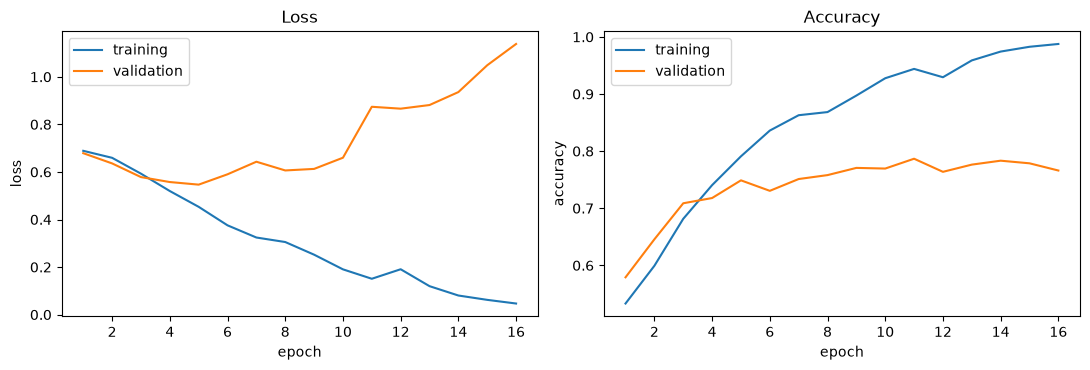

In [39]:
history = net_lstm_last.history
epochs = np.arange(1, len(history) + 1)
print(f"best validation accuracy {max(history[:, 'valid_acc']):.3f} at epoch {np.argmax(history[:, 'valid_acc']) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, history[:, "train_loss"], label="training")
axes[0].plot(epochs, history[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, history[:, "train_acc"], label="training")
axes[1].plot(epochs, history[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### GRU

The same network, with a `GRU` layer.

In [40]:
class GRUClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBEDDING, padding_idx=0)
        self.gru = nn.GRU(EMBEDDING, HIDDEN, batch_first=True)
        self.out = nn.Linear(HIDDEN, 2)  # one output for each class

    def forward(self, ids):
        lengths = (ids != 0).sum(dim=1).clamp(min=1)  # the real length of every sentence
        states, _ = self.gru(self.embedding(ids))  # one hidden state for every word
        last = states[torch.arange(len(ids), device=ids.device), lengths - 1]  # the state of the last word
        return self.out(last)

In [44]:
torch.manual_seed(0)
net_gru_last = NeuralNetClassifier(
    GRUClassifier,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    lr=2e-3,
    batch_size=BATCH,
    max_epochs=MAX_EPOCHS,
    iterator_train__shuffle=True,  # skorch does not shuffle the training sentences by default
    train_split=predefined_split(valid_ds),
    callbacks=[
        EpochScoring(scoring="accuracy", name="train_acc", on_train=True, lower_is_better=False),
        EarlyStopping(monitor="valid_acc", patience=5, lower_is_better=False, load_best=True),
    ],
    device=DEVICE,
)

In [42]:
net_gru_last.fit(X_train, y_train)
nets["gru, last state"] = net_gru_last

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5481        0.6860       0.5952        0.6707  1.0707
      2       0.6043        0.6611       0.6181        0.6384  1.0250
      3       0.6814        0.5986       0.6789        0.5951  0.9993
      4       0.7406        0.5295       0.6995        0.6152  1.0240
      5       0.7815        0.4660       0.7408        0.5522  1.0830
      6       0.8237        0.3979       0.7397        0.5438  0.9858
      7       0.8588        0.3326       0.7626        0.5704  1.0341
      8       0.8897        0.2751       0.7672        0.5947  1.0082
      9       0.8960        0.2535       0.7741        0.6143  1.0569
     10       0.9321        0.1820       0.7867        0.7161  1.0020
     11       0.9553        0.1325       0.7787        0.8414  1.0028
     12       0.9623        0.1135       0.7741        0.7849  1.0955
     13       0.9733

best validation accuracy 0.787 at epoch 10


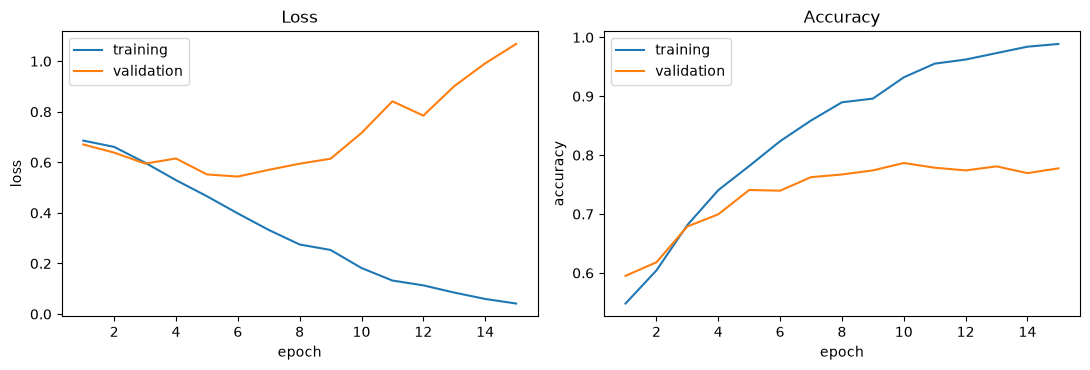

In [43]:
history = net_gru_last.history
epochs = np.arange(1, len(history) + 1)
print(f"best validation accuracy {max(history[:, 'valid_acc']):.3f} at epoch {np.argmax(history[:, 'valid_acc']) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, history[:, "train_loss"], label="training")
axes[0].plot(epochs, history[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, history[:, "train_acc"], label="training")
axes[1].plot(epochs, history[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

With the **last state** the three cells are close to each other. The sentences are short (about 20 words), so the gradient goes back only a few steps and the vanilla RNN has no big problem. The curves are similar for all of them: the training accuracy goes towards 1 and the validation loss goes up after 2 or 3 epochs. The networks **overfit**: with 6,920 sentences they memorize the training set, and early stopping ends the training and restores the weights of the best epoch. The LSTM and the GRU are a little better than the vanilla RNN, but with 872 validation sentences a difference of one or two points is within the noise: with another seed the order can change.

---
## The last state or the mean of the states

The last hidden state has to carry the information of the **whole** sentence. We try the mean of the states of all the words instead.

### LSTM, mean of the states

In [45]:
class LSTMMeanClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), EMBEDDING, padding_idx=0)
        self.lstm = nn.LSTM(EMBEDDING, HIDDEN, batch_first=True)
        self.out = nn.Linear(HIDDEN, 2)  # one output for each class

    def forward(self, ids):
        mask = (ids != 0).float()[:, :, None]  # 1 for the words, 0 for the padding
        states, _ = self.lstm(self.embedding(ids))  # one hidden state for every word
        mean = (states * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)  # the mean of the states of the words
        return self.out(mean)

In [46]:
torch.manual_seed(0)
net_lstm_mean = NeuralNetClassifier(
    LSTMMeanClassifier,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    lr=2e-3,
    batch_size=BATCH,
    max_epochs=MAX_EPOCHS,
    iterator_train__shuffle=True,  # skorch does not shuffle the training sentences by default
    train_split=predefined_split(valid_ds),
    callbacks=[
        EpochScoring(scoring="accuracy", name="train_acc", on_train=True, lower_is_better=False),
        EarlyStopping(monitor="valid_acc", patience=5, lower_is_better=False, load_best=True),
    ],
    device=DEVICE,
)

In [47]:
net_lstm_mean.fit(X_train, y_train)
nets["lstm, mean"] = net_lstm_mean

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5620        0.6813       0.6124        0.6605  0.4899
      2       0.6309        0.6346       0.6778        0.5946  0.4715
      3       0.7094        0.5639       0.7110        0.5633  0.4644
      4       0.7556        0.4954       0.7122        0.5383  0.4796
      5       0.7955        0.4431       0.7477        0.5057  0.4790
      6       0.8360        0.3703       0.7569        0.5103  0.4772
      7       0.8647        0.3202       0.7695        0.5124  0.4860
      8       0.8893        0.2766       0.7752        0.5244  0.4590
      9       0.9126        0.2225       0.7683        0.6178  0.4729
     10       0.9289        0.1857       0.7649        0.6465  0.4720
     11       0.9477        0.1425       0.7741        0.6870  0.5263
     12       0.9562        0.1207       0.7557        0.8443  0.4633
Stopping since valid

best validation accuracy 0.775 at epoch 8


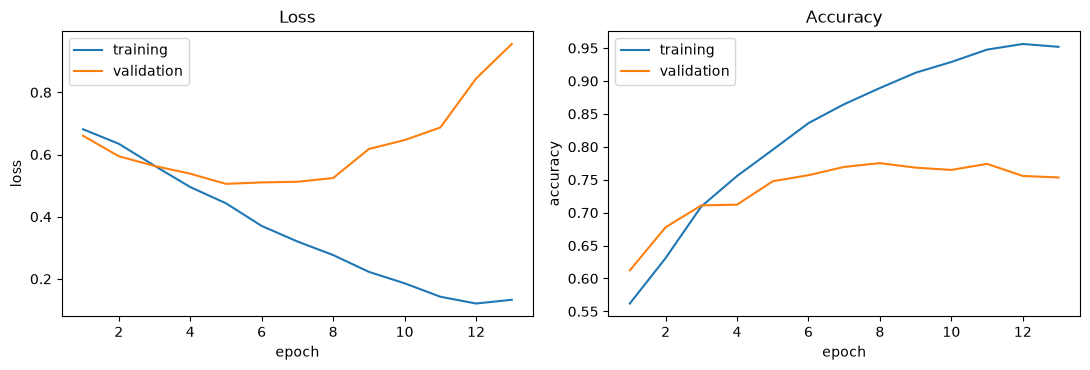

In [48]:
history = net_lstm_mean.history
epochs = np.arange(1, len(history) + 1)
print(f"best validation accuracy {max(history[:, 'valid_acc']):.3f} at epoch {np.argmax(history[:, 'valid_acc']) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, history[:, "train_loss"], label="training")
axes[0].plot(epochs, history[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, history[:, "train_acc"], label="training")
axes[1].plot(epochs, history[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

The mean of the states helps a little: every word has a **direct path** to the output, so the information does not have to travel through all the steps up to the last one. The difference is small here because the sentences are short. On long documents the last state is much harder to train, and the mean (or an attention mechanism) becomes more important.

---
## Pretrained word vectors

So far the embeddings start from random numbers and are learned together with the rest of the network, from 6,920 sentences only. We can start instead from **GloVe** vectors, trained on billions of words (50 dimensions; the download is around 70 MB and needs an internet connection). The words that GloVe does not know keep a random vector.

In [49]:
glove = api.load("glove-wiki-gigaword-50")

torch.manual_seed(0)
pretrained = torch.randn(len(vocab), EMBEDDING) * 0.1
pretrained[0] = 0
found = 0
for i, w in enumerate(vocab):
    if w in glove:
        pretrained[i] = torch.tensor(glove[w])
        found += 1
print(f"{found} of {len(vocab)} words have a pretrained vector")

7063 of 7142 words have a pretrained vector


### LSTM, mean of the states, GloVe

The embedding layer is created with `nn.Embedding.from_pretrained`: it starts from the GloVe vectors and is still **trained** (`freeze=False`). The vectors are passed to the network when we define it, with `module__pretrained`.

In [53]:
class LSTMGloVeClassifier(nn.Module):
    def __init__(self, pretrained):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(pretrained.clone(), freeze=False, padding_idx=0)  # a copy of the GloVe vectors
        self.lstm = nn.LSTM(EMBEDDING, HIDDEN, batch_first=True)
        self.out = nn.Linear(HIDDEN, 2)  # one output for each class

    def forward(self, ids):
        mask = (ids != 0).float()[:, :, None]  # 1 for the words, 0 for the padding
        states, _ = self.lstm(self.embedding(ids))  # one hidden state for every word
        mean = (states * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)  # the mean of the states of the words
        return self.out(mean)

In [54]:
torch.manual_seed(0)
net_lstm_glove = NeuralNetClassifier(
    LSTMGloVeClassifier,
    module__pretrained=pretrained,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    lr=2e-3,
    batch_size=BATCH,
    max_epochs=MAX_EPOCHS,
    iterator_train__shuffle=True,  # skorch does not shuffle the training sentences by default
    train_split=predefined_split(valid_ds),
    callbacks=[
        EpochScoring(scoring="accuracy", name="train_acc", on_train=True, lower_is_better=False),
        EarlyStopping(monitor="valid_acc", patience=5, lower_is_better=False, load_best=True),
    ],
    device=DEVICE,
)

In [55]:
net_lstm_glove.fit(X_train, y_train)
nets["lstm, mean, GloVe"] = net_lstm_glove

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5945        0.6637       0.6869        0.5993  0.5008
      2       0.7160        0.5662       0.7489        0.5022  0.4650
      3       0.7962        0.4368       0.7718        0.4583  0.4775
      4       0.8491        0.3456       0.7775        0.4784  0.5314
      5       0.8831        0.2802       0.7970        0.4661  0.4902
      6       0.9097        0.2249       0.7982        0.4814  0.4572
      7       0.9324        0.1790       0.8005        0.5616  0.5569
      8       0.9475        0.1447       0.7890        0.5504  0.4935
      9       0.9585        0.1126       0.7982        0.6630  0.4876
     10       0.9733        0.0800       0.7959        0.6962  0.4954
     11       0.9796        0.0689       0.7993        0.7651  0.4778
Stopping since valid_acc has not improved in the last 5 epochs.
Restoring best model from 

best validation accuracy 0.800 at epoch 7


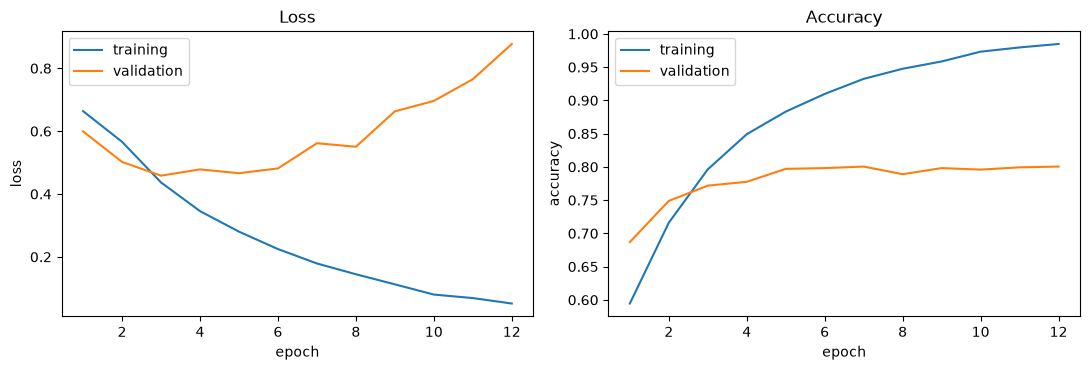

In [56]:
history = net_lstm_glove.history
epochs = np.arange(1, len(history) + 1)
print(f"best validation accuracy {max(history[:, 'valid_acc']):.3f} at epoch {np.argmax(history[:, 'valid_acc']) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, history[:, "train_loss"], label="training")
axes[0].plot(epochs, history[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, history[:, "train_acc"], label="training")
axes[1].plot(epochs, history[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Starting from GloVe vectors is the change that helps most: the best epoch is one of the first, and the validation accuracy goes up by a few points. The vectors bring information learned from a lot of text, which 6,920 sentences cannot give: many words of the vocabulary appear only a few times in the training set.

---
## The test set

We take the model with the best validation accuracy and evaluate it **once** on the test sentences, next to the baseline.

In [57]:
summary = pd.Series({name: max(net.history[:, "valid_acc"]) for name, net in nets.items()}, name="best validation accuracy")
print(summary.sort_values(ascending=False).round(3).to_string())

best = summary.idxmax()
print()
print(f"best model: {best}")
print(f"test accuracy of the best model: {nets[best].score(X_test, y_test):.3f}")
print(f"test accuracy of the baseline (TF-IDF + logistic regression): {baseline.score(tfidf.transform(test.text), y_test):.3f}")

lstm, mean, GloVe    0.800
lstm, last state     0.787
gru, last state      0.787
lstm, mean           0.775
rnn, last state      0.750

best model: lstm, mean, GloVe
test accuracy of the best model: 0.801
test accuracy of the baseline (TF-IDF + logistic regression): 0.796


---
# Exercises

- **Short and long sentences.** Split the validation sentences in short (fewer than 10 words) and long (more than 30 words), and compute the accuracy of the best model on each group. Is a long sentence harder?
- **The size.** Change `HIDDEN` (for example 16 and 256). Does a larger state always help?
- **Clipping.** Add `GradientNormClipping(1.0)` (from `skorch.callbacks`) to the callbacks of the vanilla RNN. It scales down the gradient when its norm is larger than 1. Does the training change?
- **Bidirectional.** Use `bidirectional=True` in the LSTM. The output of the cell has twice as many numbers: change the linear layer. For the last state you need the states of both directions, so start with the mean of the states.
- **Frozen vectors.** Freeze the GloVe embeddings (`freeze=True` in `nn.Embedding.from_pretrained`). Is it better or worse than fine-tuning them?
